
# APTOS 2019 Dataset Exploration

## Project: Diabetic Retinopathy Detection System

### Objectives
1. Load the APTOS dataset.
2. Explore training and testing CSV files.
3. Analyze DR severity distribution.
4. Visualize retinal fundus images.
5. Inspect image dimensions and quality.
6. Verify image IDs against CSV labels.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import os

# Dataset path (notebook is inside notebooks/)
BASE = Path("../data/raw/aptos/aptos2019-blindness-detection")

TRAIN_DIR = BASE / "train_images"
TEST_DIR = BASE / "test_images"

train_df = pd.read_csv(BASE / "train.csv")
test_df = pd.read_csv(BASE / "test.csv")

print("Dataset loaded successfully!")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining CSV:")
display(train_df.head())

print("\nTesting CSV:")
display(test_df.head())


Dataset loaded successfully!
Training records: 3662
Testing records: 1928

Training CSV:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Testing CSV:


,id_code
0,0005cfc8afb6
1,003f0afdcd15
2,006efc72b638
3,00836aaacf06
4,009245722fa4


DR Class Distribution:


diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

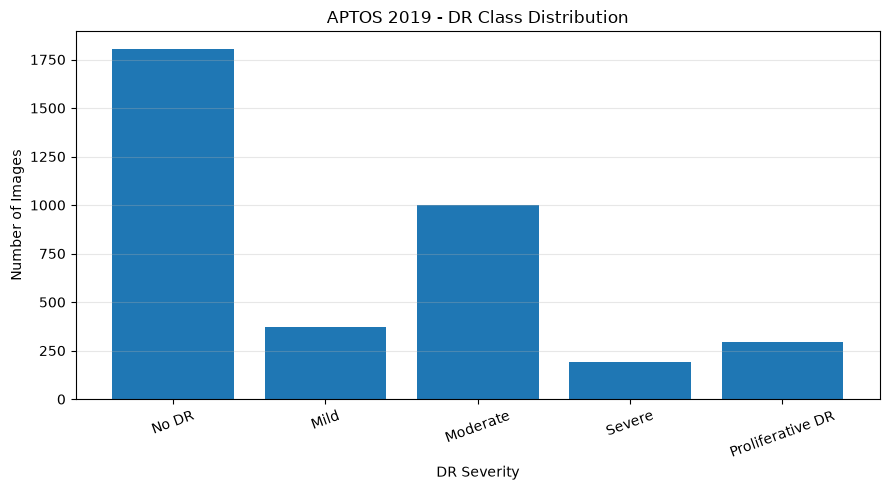

In [2]:

# Count images in each DR grade
class_counts = train_df["diagnosis"].value_counts().sort_index()

grade_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("DR Class Distribution:")
display(class_counts)

plt.figure(figsize=(9, 5))
plt.bar(grade_names, class_counts.values)

plt.title("APTOS 2019 - DR Class Distribution")
plt.xlabel("DR Severity")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


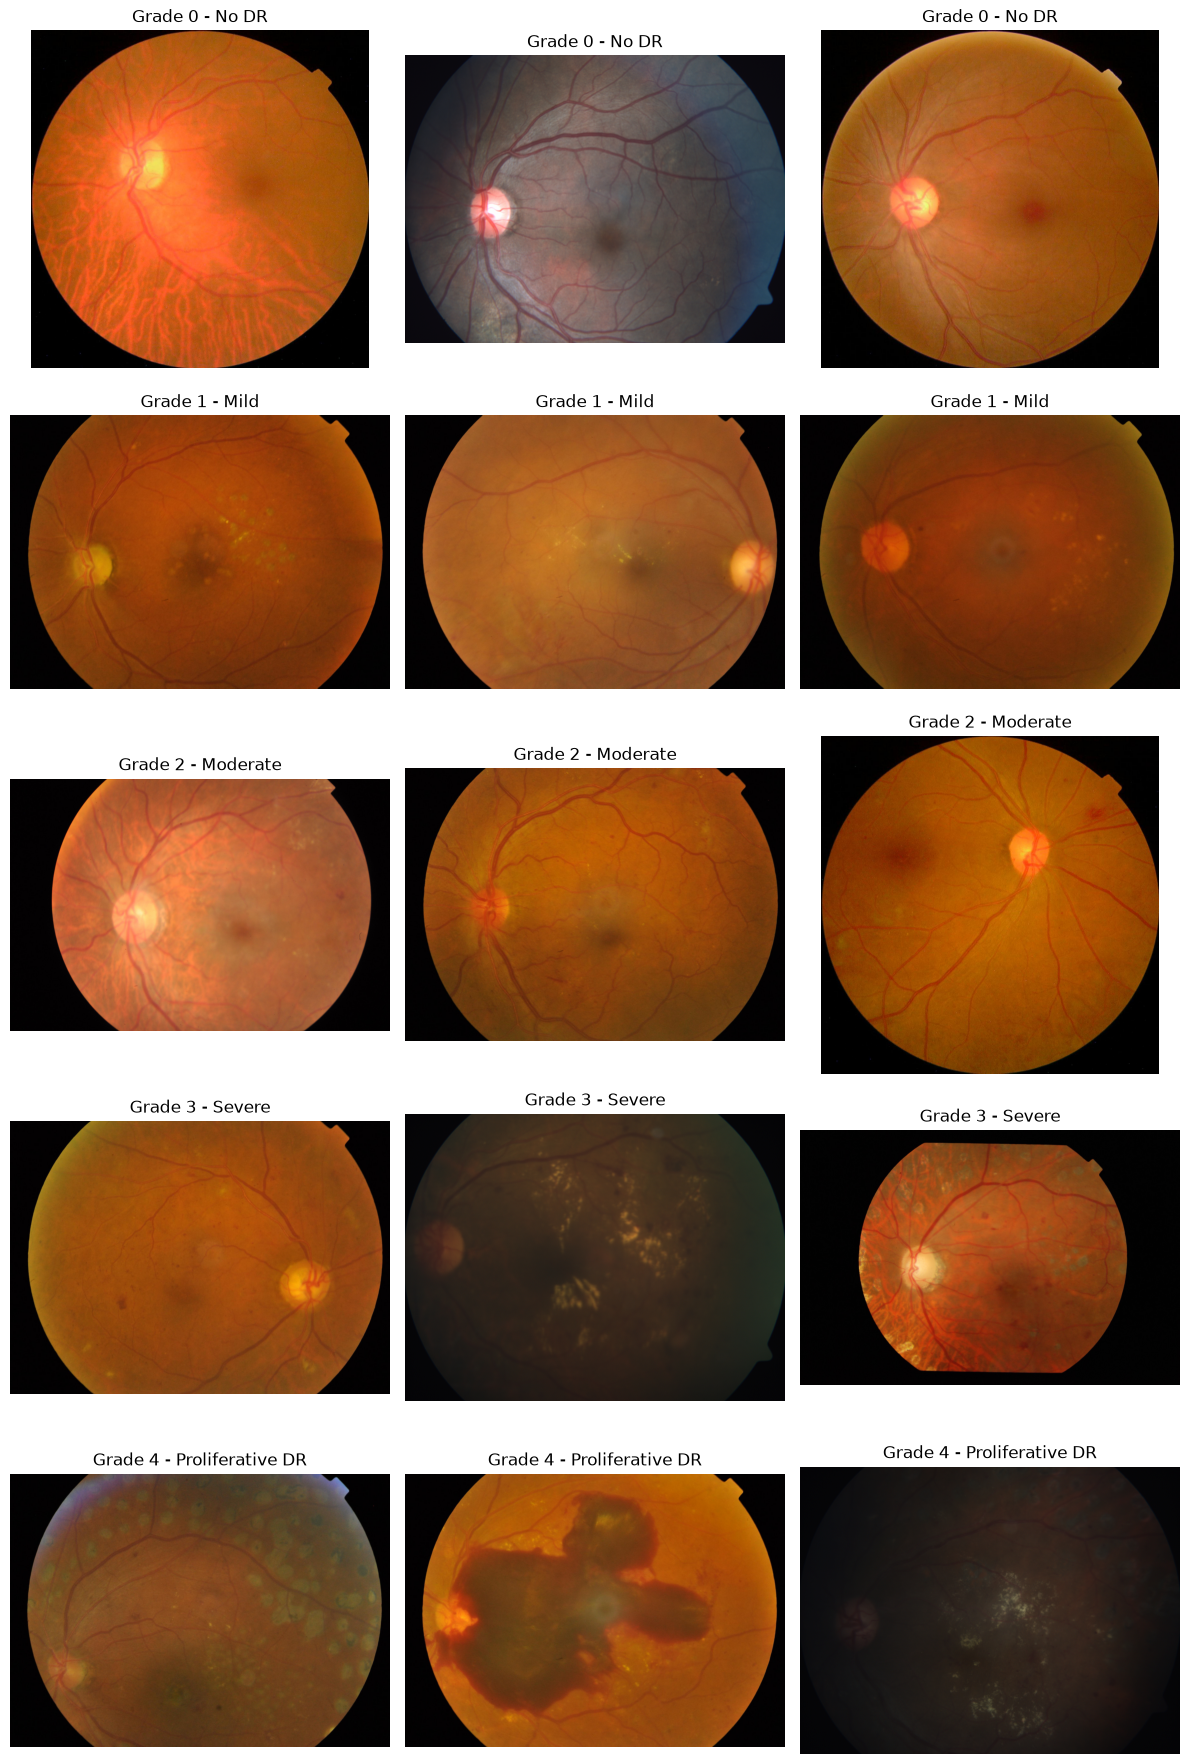

In [3]:

fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for grade in range(5):

    samples = train_df[
        train_df["diagnosis"] == grade
    ].sample(n=3, random_state=42)

    for col, (_, row) in enumerate(samples.iterrows()):

        image_path = TRAIN_DIR / (row["id_code"] + ".png")

        with Image.open(image_path) as img:
            axes[grade, col].imshow(img.convert("RGB"))

        axes[grade, col].set_title(
            f"Grade {grade} - {grade_names[grade]}"
        )

        axes[grade, col].axis("off")

plt.tight_layout()
plt.show()


In [4]:

# Verify CSV IDs against actual image filenames
train_ids = set(train_df["id_code"].astype(str))
actual_ids = {
    p.stem for p in TRAIN_DIR.glob("*.png")
}

missing_images = train_ids - actual_ids
extra_images = actual_ids - train_ids

print("Training IDs:", len(train_ids))
print("Actual training images:", len(actual_ids))
print("Missing images:", len(missing_images))
print("Extra images:", len(extra_images))

# Check image dimensions
dimensions = []

for path in TRAIN_DIR.glob("*.png"):
    with Image.open(path) as img:
        dimensions.append(img.size)

dimension_df = pd.Series(
    dimensions, name="Image Dimensions"
).value_counts()

print("\nMost common image dimensions:")
display(dimension_df.head(10))


Training IDs: 3662
Actual training images: 3662
Missing images: 0
Extra images: 0

Most common image dimensions:


Image Dimensions
(1050, 1050)    974
(2416, 1736)    638
(2588, 1958)    533
(3216, 2136)    410
(2048, 1536)    351
(819, 614)      287
(3388, 2588)    141
(1504, 1000)     92
(1844, 1226)     61
(4288, 2848)     52
Name: count, dtype: int64